# 17 · Age of the view check and newer checks (E44-E45)

Views are checked from 7 h to months after posting and keep growing (E38-E39). Two questions:
1. Does the final model improve when it knows how old the post was at the check (E44)?
2. Are the newer checks from the history file (`current_*`) more predictable than the old ones (E45)?

Final model as in notebook 14: CatBoost with MAE loss on followers + reactions + missing flags. 5-fold brand-grouped CV, MAE of log10(views), paired brand bootstrap CI.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu, history as H, check_age as ca

FIG = ROOT / "figures"; plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220, "display.max_columns", 30)
B, A, R = "final model", "final model + check age", "final model + check age, refreshed data"

In [2]:
f, meta, g, m2 = ca.load(ROOT)

## 1 · Data
Age of the check per platform, and how many posts get a newer check from the history file.

In [3]:
t = meta.groupby("platform").agg(posts=("y", "size"), median_age_h=("age_h", "median"), refreshed=("refreshed", "sum"), views_grew=("views_grew", "sum"))
t.loc["TOTAL"] = [len(meta), meta.age_h.median(), meta.refreshed.sum(), meta.views_grew.sum()]; t

,posts,median_age_h,refreshed,views_grew
platform,,,,
tiktok,2491,858.271944,348,133
twitter,1803,504.628889,342,33
youtube,2441,605.007222,503,201
TOTAL,6735,679.289722,1193,367


## 2 · E44: the age of the check as a column

In [4]:
P = ca.run(f, meta, g, m2); T = H.summarise(P); T.round(3)

,platform,model,posts,MAE,CI low,CI high,bias
0,tiktok,final model,2491,0.273,0.263,0.285,-0.020
1,tiktok,final model + check age,2491,0.273,0.262,0.285,-0.020
2,tiktok,"final model + check age, refreshed data",2491,0.274,0.264,0.287,-0.019
3,youtube,final model,2441,0.456,0.434,0.480,-0.039
4,youtube,final model + check age,2441,0.452,0.432,0.474,-0.038
5,youtube,"final model + check age, refreshed data",2441,0.454,0.434,0.476,-0.031
6,twitter,final model,1803,0.466,0.446,0.489,-0.039
7,twitter,final model + check age,1803,0.454,0.435,0.474,-0.041
8,twitter,"final model + check age, refreshed data",1803,0.465,0.446,0.486,-0.039


In [5]:
G = pd.DataFrame([{"platform": p, "comparison": f"{a} -> {b}", "subset": s, **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(Q, p, a, b)))}
                  for s, Q in [("all posts", P), ("refreshed posts", ca.subset(P))] for p in ca.PLATS for a, b in [(B, A), (A, R)]]); G.round(3)

,platform,comparison,subset,gain,CI low,CI high
0,tiktok,final model -> final model + check age,all posts,0.000,-0.002,0.003
1,tiktok,final model + check age -> final model + check...,all posts,-0.001,-0.003,-0.000
2,youtube,final model -> final model + check age,all posts,0.003,-0.001,0.008
3,youtube,final model + check age -> final model + check...,all posts,-0.002,-0.005,0.002
4,twitter,final model -> final model + check age,all posts,0.012,0.005,0.019
5,twitter,final model + check age -> final model + check...,all posts,-0.011,-0.015,-0.007
6,tiktok,final model -> final model + check age,refreshed posts,-0.001,-0.009,0.006
7,tiktok,final model + check age -> final model + check...,refreshed posts,-0.010,-0.017,-0.002
8,youtube,final model -> final model + check age,refreshed posts,0.022,0.010,0.033
9,youtube,final model + check age -> final model + check...,refreshed posts,0.006,-0.011,0.020


In [6]:
Y = ca.by_age(P).merge(ca.by_age(P, A), on=["platform", "age", "posts"], suffixes=("", " +age")); Y.round(3)

,platform,age,posts,MAE,bias,MAE +age,bias +age
0,tiktok,<1 d,53.0,0.385,0.226,0.341,0.069
1,tiktok,1-7 d,113.0,0.308,0.101,0.312,0.019
2,tiktok,7-30 d,969.0,0.262,-0.031,0.262,-0.036
3,tiktok,30-90 d,1086.0,0.277,-0.023,0.279,-0.011
4,tiktok,>90 d,270.0,0.263,-0.066,0.259,-0.031
5,twitter,<1 d,531.0,0.458,-0.016,0.410,-0.081
6,twitter,1-7 d,138.0,0.535,-0.130,0.526,-0.020
7,twitter,7-30 d,371.0,0.458,-0.103,0.458,-0.026
8,twitter,30-90 d,732.0,0.464,-0.000,0.468,-0.018
9,twitter,>90 d,31.0,0.478,-0.199,0.520,-0.186


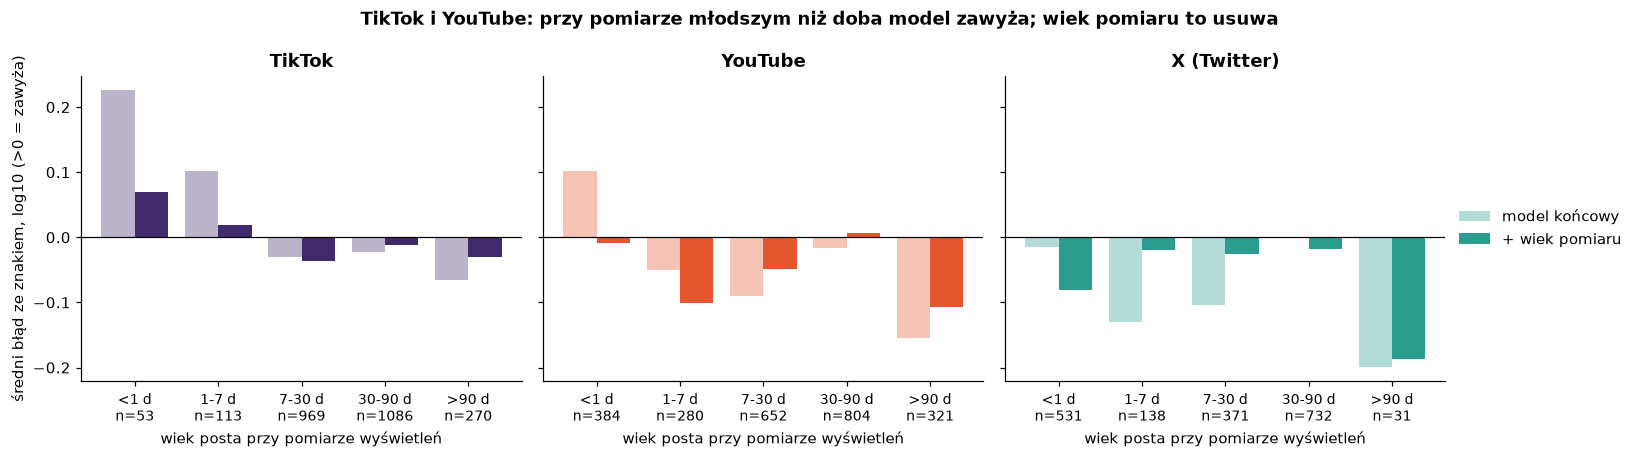

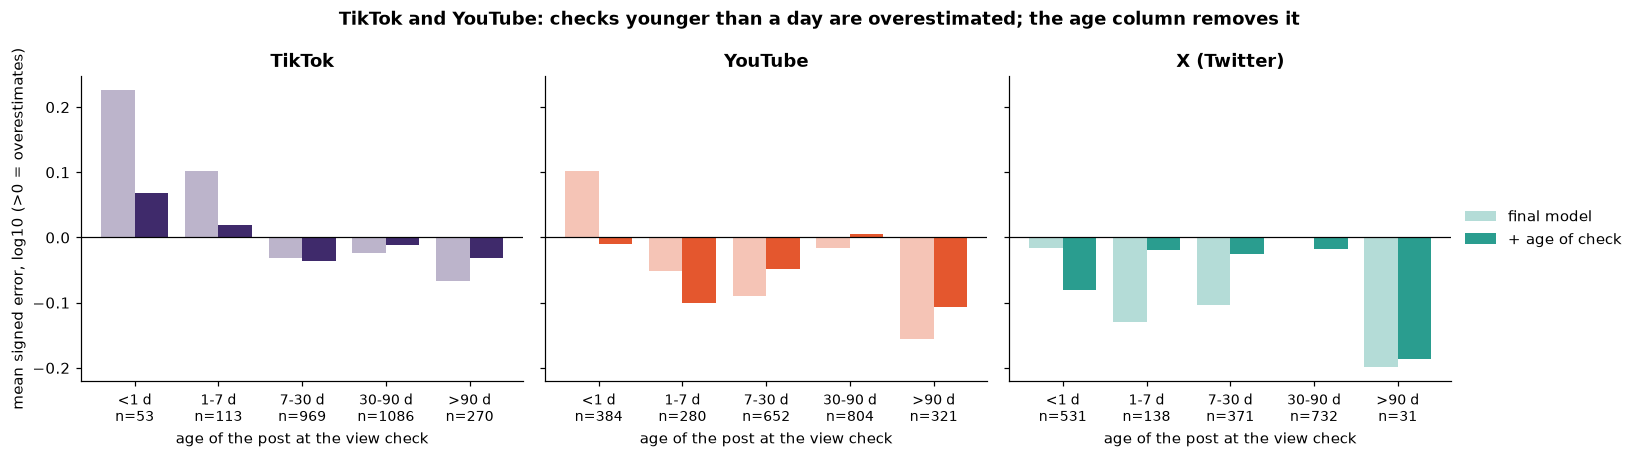

In [7]:
for l in ("pl", "en"): ca.plot_bias(P, FIG / f"check_age_bias_{l}.png", l)

## 3 · E45: newer checks
See the second comparison in the table above (`+ check age` against the same model on refreshed data). The target changes with the data, so this measures how predictable the data are, not a model gain.

In [8]:
S = H.summarise(ca.subset(P)); S.round(3)

,platform,model,posts,MAE,CI low,CI high,bias
0,tiktok,final model,348,0.286,0.256,0.315,-0.011
1,tiktok,final model + check age,348,0.287,0.254,0.316,-0.044
2,tiktok,"final model + check age, refreshed data",348,0.296,0.264,0.326,-0.049
3,youtube,final model,503,0.457,0.419,0.499,-0.017
4,youtube,final model + check age,503,0.435,0.400,0.475,-0.029
5,youtube,"final model + check age, refreshed data",503,0.429,0.395,0.469,-0.078
6,twitter,final model,342,0.456,0.415,0.498,-0.059
7,twitter,final model + check age,342,0.417,0.377,0.457,-0.075
8,twitter,"final model + check age, refreshed data",342,0.463,0.421,0.505,-0.067


## Takeaways
See `docs/en/experiments.md` (E44-E45) and `agent/vault/E44.md`, `E45.md`. Numbers: `data/processed/check_age_numbers.json`.

In [9]:
json.dump({"data": t.reset_index().to_dict("records"), "models": T.to_dict("records"), "gains": G.to_dict("records"), "by_age": Y.astype({"age": str}).to_dict("records"), "refreshed_subset": S.to_dict("records")},
          open(ROOT / "data" / "processed" / "check_age_numbers.json", "w"), indent=1, default=float)